<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Сегментация изображений</b></h3>


В этом задании вам предстоит решить задачу сегментации медицинских снимков. Домашнее задание можно разделить на следующие части:

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]
* Мир других лоссов! [2]
  * Dice Loss [1]
  * Focal Loss [1]
  * BONUS: лосс из статьи [5]
* Новая модель! [2]
  * UNet [2]


**Максимальный балл:** 10 баллов.

Также для студентов желающих еще более углубиться в задачу предлагается решить бонусное задание, которое даст дополнительные 5 баллов. BONUS задание необязательное.


# Шаг 1. Загрузка и подготовка данных

1. Для начала мы скачаем датасет: [ADDI project](https://www.fc.up.pt/addi/ph2%20database.html).

<table><tr><td>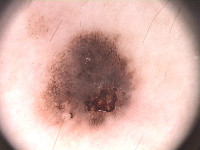</td><td>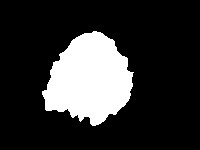</td></tr></table>

2. Разархивируем .rar файл.
3. Обратите внимание, что папка  `PH2 Dataset images` должна лежать там же где и ipynb notebook.

Это фотографии двух типов **поражений кожи:** меланома и родинки.
В данном задании мы не будем заниматься их классификацией, а будем **сегментировать** их.

In [1]:
!gdown 1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql

Downloading...
From (original): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql
From (redirected): https://drive.google.com/uc?id=1T_RPkPP0jeWwK8L1UrmBw8V30eD7v6Ql&confirm=t&uuid=0b3c3233-9f87-4f2b-977b-349eacd316e3
To: /content/PH2Dataset.rar
100% 162M/162M [00:02<00:00, 54.2MB/s]


In [2]:
get_ipython().system_raw("unrar x PH2Dataset.rar")

Стуктура датасета у нас следующая:

    IMD_002/
        IMD002_Dermoscopic_Image/
            IMD002.bmp
        IMD002_lesion/
            IMD002_lesion.bmp
        IMD002_roi/
            ...
    IMD_003/
        ...
        ...

 Здесь `X.bmp` — изображение, которое нужно сегментировать, `X_lesion.bmp` — результат сегментации.

Для загрузки датасета можно использовать skimage: [`skimage.io.imread()`](https://scikit-image.org/docs/dev/api/skimage.io.html)

In [3]:
images = []
lesions = []
from skimage.io import imread
import os
root = 'PH2Dataset'

for root, dirs, files in os.walk(os.path.join(root, 'PH2 Dataset images')):
    if root.endswith('_Dermoscopic_Image'):
        images.append(imread(os.path.join(root, files[0])))
    if root.endswith('_lesion'):
        lesions.append(imread(os.path.join(root, files[0])))

Изображения имеют разные размеры. Давайте изменим их размер на $256\times256 $ пикселей. Для изменения размера изображений можно использовать [`skimage.transform.resize()`](https://scikit-image.org/docs/dev/api/skimage.transform.html#skimage.transform.resize).
Эта функция также автоматически нормализует изображения в диапазоне $[0,1]$.


In [4]:
from skimage.transform import resize
size = (256, 256)
X = [resize(x, size, mode='constant', anti_aliasing=True,) for x in images]
Y = [resize(y, size, mode='constant', anti_aliasing=False) > 0.5 for y in lesions]

In [5]:
import numpy as np
X = np.array(X, np.float32)
Y = np.array(Y, np.float32)
print(f'Loaded {len(X)} images')

Loaded 200 images


Чтобы убедиться, что все корректно, мы нарисуем несколько изображений

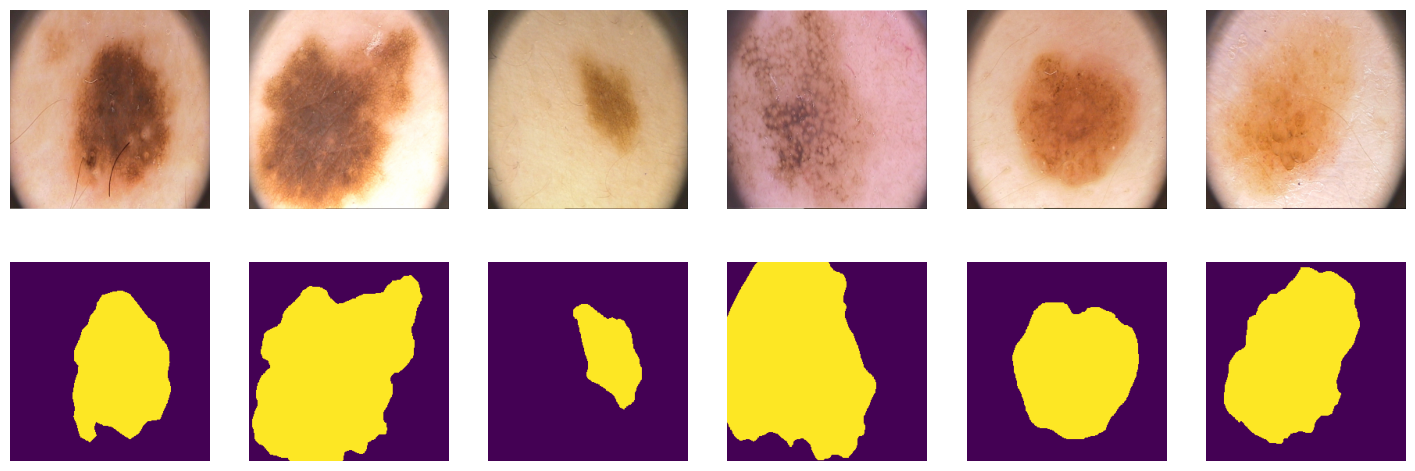

In [6]:
import matplotlib.pyplot as plt
from IPython.display import clear_output

plt.figure(figsize=(18, 6))
for i in range(6):
    plt.subplot(2, 6, i+1)
    plt.axis("off")
    plt.imshow(X[i])

    plt.subplot(2, 6, i+7)
    plt.axis("off")
    plt.imshow(Y[i])
plt.show();

Разделим наши 200 картинок на 100/50/50
 для обучения, валидации и теста соответственно

In [7]:
ix = np.random.choice(len(X), len(X), False)
tr, val, ts = np.split(ix, [100, 150])

In [8]:
print(len(tr), len(val), len(ts))

100 50 50


## PyTorch DataLoader

In [9]:
from torch.utils.data import DataLoader
batch_size = 25
train_dataloader = DataLoader(list(zip(np.rollaxis(X[tr], 3, 1), Y[tr, np.newaxis])),
                     batch_size=batch_size, shuffle=True)
valid_dataloader = DataLoader(list(zip(np.rollaxis(X[val], 3, 1), Y[val, np.newaxis])),
                      batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(list(zip(np.rollaxis(X[ts], 3, 1), Y[ts, np.newaxis])),
                     batch_size=batch_size, shuffle=False)

In [10]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Шаг 2. Метрика качества модели

## IoU (intersection over union)

В данном разделе предлагается использовать следующую метрику для оценки качества:

$I o U=\frac{\text {target } \cap \text { prediction }}{\text {target } \cup{prediction }}$

Пересечение (A ∩ B) состоит из пикселей, найденных как в маске предсказания, так и в основной маске истины, тогда как объединение (A ∪ B) просто состоит из всех пикселей, найденных либо в маске предсказания, либо в целевой маске.


Что будет являться пересением и объединением в задаче сегментации?

Давайте разберем следующий пример:





<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1rBYFgli48AUUN9idiyq8j3J5DboB93yN" width=1000 height=800/></p>

In [11]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 16.2 MB/s eta 0:00:00


In [12]:
from torchmetrics import JaccardIndex

iou_score = JaccardIndex(threshold=0.5, task="binary", average='none').to(device)

# Задания: Построй свой первый бейзлайн!

Итак, загрузка файлов, код датасета и даталоадера написана за вас. Метрика IoU написана за вас! Вам остается написать лосс, модель и функции обучения и теста модели.

* Построй свой первый бейзлайн! [6]
  * BCE Loss [2]
  * SegNet [2]
  * Train [1]
  * Test [1]

## Шаг 3. Loss функция - BCE [2 балла]

Популярным лоссом для бинарной сегментации является *бинарная кросс-энтропия*, которая задается следующим образом:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

где $y$ это  таргет желаемого результата и $\hat y$ является выходом модели. $\sigma$ - это [*логистическая* функция](https://en.wikipedia.org/wiki/Sigmoid_function), который преобразует действительное число $\mathbb R$ в вероятность $[0,1]$.

Однако эта потеря страдает от проблем численной нестабильности. Самое главное, что $\lim_{x\rightarrow0}\log(x)=\infty$ приводит к неустойчивости в процессе оптимизации. Рекомендуется посмотреть следующее [упрощение](https://www.tensorflow.org/api_docs/python/tf/nn/sigmoid_cross_entropy_with_logits). Эта функция эквивалентна первой и не так подвержена численной неустойчивости:

$$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right) \space [2]$$

### Вывод численно стабильной формулы BCE лосса [1 балл]



Выведите из формулы [1] формулу [2]:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right] \space [1]$$

$$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right) \space [2]$$

Не забываем, что здесь $\hat y_i$ - это логиты сети, не вероятности и не лейблы.

**Ответ:**

### Реализуйте в коде оба варианта лосса [1 балл]

Реализуйте следующие функции:

*   `bce_true()` - честная прямая реализация лосса с формулой $$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$
*   `bce_loss()` - реализация формулы, которую мы вывели $$\mathcal L_{BCE} = \hat y - y\hat y + \log\left(1+\exp(-\hat y)\right).$$

И сравните результаты функций с реализацией Pytorch:
*   `bce_torch()`
*   `bce_torch_with_logits()`

In [13]:
import torch.nn.functional as F
import torch.nn as nn

In [14]:
bce_torch = nn.BCELoss(reduction='sum') # (sigmoid(y_pred), y_real)
bce_torch_with_logits = nn.BCEWithLogitsLoss(reduction='sum')

In [15]:
def bce_loss(y_pred, y_real):
  eps = 1e-8
  p = torch.sigmoid(y_pred)
  loss = -(y_real * torch.log(p + eps) + (1.0 - y_real) * torch.log(1.0 - p + eps))
  return loss.sum()

def bce_true(y_pred, y_real):
  loss = y_pred - y_pred * y_real + torch.log1p(torch.exp(-y_pred))
  return loss.sum()

Проверим корректность работы на простом примере

In [16]:
y_pred = torch.randn(3, 2, requires_grad=False)
y_true = torch.rand(3, 2, requires_grad=False)

print(f'BCE loss from scratch bce_loss             = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный                = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch              = {bce_torch(torch.sigmoid(y_pred), y_true)}')
print(f'BCE loss from torch with logits bce_torch  = {bce_torch_with_logits(y_pred, y_true)}')


BCE loss from scratch bce_loss             = 3.809086799621582
BCE loss честно посчитанный                = 3.809087038040161
BCE loss from torch bce_torch              = 3.809087038040161
BCE loss from torch with logits bce_torch  = 3.809087038040161


Инструкции `assert` в Python — это булевы выражения, которые проверяют, является ли условие истинным (`True`). Внизу в коде мы проверяем функция `bce_loss()` выдает тот же результат, что и функция из Pytorch или нет. Если равенства не будет, что будет означать, что результаты функций не совпадают, а значит вы неправильно реализовали фукнцию `bce_loss()`, `assert` возвратит ошибку.

Функция `numpy.isclose()` используется для сравнения двух чисел с учётом допустимой погрешности. Она особенно полезна при работе с числами с плавающей точкой, где точное сравнение может быть проблематичным из-за ограничений представления таких чисел в компьютере.

Как она работает?

`numpy.isclose(a, b, rtol=1e-05, atol=1e-08) `принимает два числа (`a` и `b`) и сравнивает их, учитывая относительную и абсолютную погрешность. Если разница между двумя числами меньше заданного порога, функция возвращает `True`, иначе — `False`.

Параметры:

    rtol: Относительная погрешность (по умолчанию 1e-05). Используется для определения разницы относительно большего значения.
    atol: Абсолютная погрешность (по умолчанию 1e-08). Определяет минимальную разницу, которую следует учитывать.

Мы будем использовать `assert` и `numpy.isclose()` для проверки корректности нашего кода.

In [17]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true))

Давайте теперь посчитаем на простом примере, но с теми же размерностями, что и в датасете

In [18]:
y_pred = torch.randn((2, 1, 3, 3), requires_grad=False)
y_true = torch.randint(0, 2, (2, 1, 3, 3))

print(f'BCE loss from scratch bce_loss            = {bce_loss(y_pred, y_true)}')
print(f'BCE loss честно посчитанный               = {bce_true(y_pred, y_true)}')
print(f'BCE loss from torch bce_torch             = {bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float))}')
print(f'BCE loss from torch with logits bce_torch = {bce_torch_with_logits(y_pred, y_true.to(torch.float))}')

BCE loss from scratch bce_loss            = 17.90888214111328
BCE loss честно посчитанный               = 17.90888023376465
BCE loss from torch bce_torch             = 17.90888214111328
BCE loss from torch with logits bce_torch = 17.90888023376465


In [19]:
assert np.isclose(bce_loss(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_loss(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch(torch.sigmoid(y_pred), y_true.to(torch.float)))
assert np.isclose(bce_true(y_pred, y_true), bce_torch_with_logits(y_pred, y_true.to(torch.float)))

Давайте посчитаем на реальных логитах и сегментационной маске:

In [22]:
!gdown --folder 1EX0RW1TRQVkLmR1h6miCQqyhYPFyg28M

Retrieving folder contents
Processing file 1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC labels.pt
Processing file 1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I logits.pt
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1--WxvBdpMn_NOmYPf3a4au8MHzfx5baC
To: /content/for_asserts/labels.pt
100% 1.18k/1.18k [00:00<00:00, 5.84MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-0A7_CS_vKiSCkgIDJ4joThCEcFedA3I
To: /content/for_asserts/logits.pt
100% 1.18k/1.18k [00:00<00:00, 6.40MB/s]
Download completed


In [23]:
path_to_dummy_samples = '/content/for_asserts'
dummpy_sample = {'logits': torch.load(f'{path_to_dummy_samples}/logits.pt'),
                 'labels': torch.load(f'{path_to_dummy_samples}/labels.pt')}
dummpy_sample['labels'] = dummpy_sample['labels'].to(device)
dummpy_sample['logits'] = dummpy_sample['logits'].to(device)

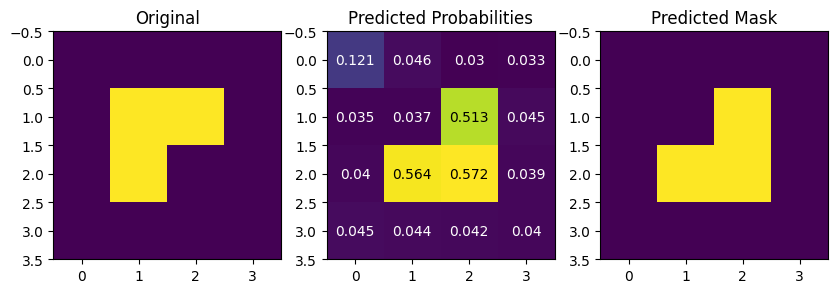

In [24]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize= (10,3*10))

ax1.imshow(dummpy_sample['labels'].squeeze(1)[0].cpu())
ax1.set_title("Original")

ax2.imshow(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu())
for (j,i),label in np.ndenumerate(dummpy_sample['logits'].sigmoid().squeeze(1)[0].cpu()):
    if label < 0.5:
        color = 'white'
    else:
        color = 'black'
    ax2.text(i,j,round(label,3), color=color, ha='center',va='center')

ax2.set_title("Predicted Probabilities")

ax3.imshow((dummpy_sample['logits'].sigmoid() > 0.5).squeeze(1)[0].cpu())
ax3.set_title("Predicted Mask")
plt.show()

Проверяем на данном примере:

In [25]:
bce_loss_score = bce_loss(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_true_score = bce_true(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu())
bce_torch_score = bce_torch(torch.sigmoid(dummpy_sample['logits'].cpu()), dummpy_sample['labels'].cpu().float())
bce_torch_with_logits_score = bce_torch_with_logits(dummpy_sample['logits'].cpu(), dummpy_sample['labels'].cpu().float())
assert np.isclose(bce_loss_score, bce_torch_score)
assert np.isclose(bce_loss_score, bce_torch_with_logits_score)
assert np.isclose(bce_true_score, bce_torch_score)
assert np.isclose(bce_true_score, bce_torch_with_logits_score)

## Шаг 4. Модель SegNet [2 балла]

Ваше задание здесь состоит в том, чтобы реализовать SegNet архитектуру.

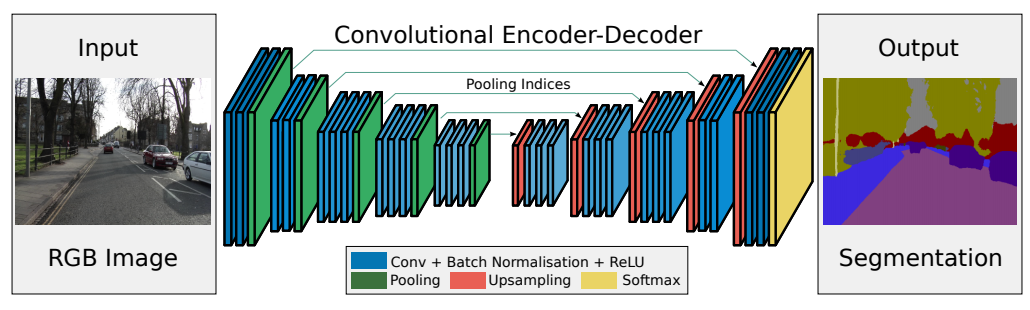

* Badrinarayanan, V., Kendall, A., & Cipolla, R. (2015). [SegNet: A deep convolutional
encoder-decoder architecture for image segmentation](https://arxiv.org/pdf/1511.00561.pdf)

In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import torch.optim as optim
from time import time

from matplotlib import rcParams
rcParams['figure.figsize'] = (15,4)

Внимательно посмотрите из чего состоит модель и для чего выбраны те или иные блоки. Для этого скачаем и изучим feature extractor VGG-16, который лежит в основе SegNet.

In [27]:
model_vgg16 = models.vgg16(weights = models.VGG16_Weights.IMAGENET1K_V1)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 139MB/s]


In [28]:
model_vgg16

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

Feature extractor VGG-16 состоит из 5 блоков:
- два блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d
- три блока со структурой:
Conv2d -> ReLU -> Conv2d -> ReLU -> Conv2d -> ReLU -> MaxPool2d

В первом блоке - на входе три канала (по числу каналов в изображениях), которые конволюционный слой преобразует в 64 канала.

Во втором, третьем и четвертом блоках первый конволюционный слой удваивает количество каналов, а последующие конволюционные слои не меняют количество каналов.

В последнем блоке число каналов от слоя к слою не меняется.

Теперь напишем код одного блока энкодера нашей модели SegNet.  

In [29]:
# Параметрами блока будут:
# - количество каналов на входе
# - количество каналов на выходе
# - глубина блока (2 или 3, по количеству конволюционных слоев)
# - kernel_size и padding
#
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, depth, kernel_size = 3, padding = 1):
        super(EncoderBlock, self).__init__() # инициируем экземляр класса, наследующего от nn.Module
        self.layers = nn.ModuleList() # в self.layers будем добавлять слои блока
        # дальше реализуем то, что на картинке выше обозначено Conv + Batch Normalization + ReLU
        self.layers.append(nn.Conv2d(in_channels = in_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
        self.layers.append(nn.BatchNorm2d(out_channels))
        self.layers.append(nn.ReLU(inplace=True))

        # цикл for помогает использовать один код для блоков как с глубиной 2, так и с глубиной 3
        for i in range(depth-1):
            self.layers.append(nn.Conv2d(in_channels = out_channels, out_channels = out_channels, kernel_size = kernel_size, padding = padding))
            self.layers.append(nn.BatchNorm2d(out_channels))
            self.layers.append(nn.ReLU(inplace=True))

        self.maxpooling = nn.MaxPool2d(kernel_size=2, stride=2, return_indices=True) #добавляем MaxPool с индексами для последующего Unpooling

    # Обратите внимание: на вход метод forward() получает карту признаков (х),
    # а возвращает карту признаков и индексы для последующего Unpooling
    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        x, indices = self.maxpooling(x)
        return x, indices


По аналогии напишите код одного блока декодера.

К карте признаков на входе каждого блока примеяется nn.MaxUnpool2d с индексами из симметричного блока энкодера. Затем повторяется связка Conv + Batch Normalization + ReLU. Количество каналов меняется зеркально блокам энкодера:
- в первом блоке декодера количество каналов не меняется
- во 2-4 блоках декодера количество каналов уменьшается в 2 раза после прохождения последнего конволюционного слоя
- на выходе из последнего блока декодера 1 канал

Обратите внимание, что после последней конволюции последнего блока декодера не применяется батч-нормализация и функция активации.

In [30]:
class DecoderBlock(nn.Module):
  def __init__(self,  in_channels, out_channels, depth, kernel_size = 3, padding = 1, last_block = False):
    super().__init__()
    self.unpool = nn.MaxUnpool2d(kernel_size=2, stride=2)
    layers = []

    for i in range(depth):
      in_ch = in_channels if i == 0 else out_channels
      is_last_conv = last_block and (i == depth - 1)

      layers.append(nn.Conv2d(in_ch, out_channels, kernel_size=kernel_size, padding=padding))

      if not is_last_conv:
        layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.ReLU(inplace=True))

    self.layers = nn.Sequential(*layers)

  def forward(self, x, indices, output_size=None):
    x = self.unpool(x, indices, output_size=output_size)
    x = self.layers(x)

    return x

Соединим блоки энкодера и декодера в модель SegNet:

In [36]:
class SegNet(nn.Module):
    def __init__(self, in_channels=3, out_channels = 1, num_features = 64) -> None:
        super(SegNet, self).__init__()

        # Encoder
        self.encoder0 = EncoderBlock(in_channels, num_features, depth=2)
        self.encoder1 = EncoderBlock(num_features, num_features * 2, depth=2)
        self.encoder2 = EncoderBlock(num_features * 2, num_features * 2**2, depth=3)# TODO
        self.encoder3 = EncoderBlock(num_features * 2**2, num_features * 2**3, depth=3)# TODO

        # Encoder bottleneck - количество каналов на входе и на выходе одинаково
        self.encoder4 = EncoderBlock(num_features * 2**3, num_features * 2**3, depth=3)# TODO

        # Decoder bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(num_features * 2**3, num_features * 2**3, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_features * 2**3),
            nn.ReLU(inplace=True)
        ) # TODO

        # Decoder
        self.decoder4 =  DecoderBlock(num_features * 2**3, num_features * 2**3, depth=3)
        self.decoder3 = DecoderBlock(num_features * 2**3, num_features * 2**2, depth=3)
        self.decoder2 = DecoderBlock(num_features * 2**2, num_features * 2, depth=3)
        self.decoder1 = DecoderBlock(num_features * 2, num_features, depth=2)
        self.decoder0 = DecoderBlock(num_features, out_channels, depth=2, last_block=True) # TODO

    def forward(self, x):
        # encoder
        x, indices0 = self.encoder0(x)
        x, indices1 = self.encoder1(x)
        x, indices2 = self.encoder2(x)
        x, indices3 = self.encoder3(x)
        x, indices4 = self.encoder4(x) # TODO

        x = self.bottleneck(x)

        # decoder
        x = self.decoder4(x, indices4)
        x = self.decoder3(x, indices3)
        x = self.decoder2(x, indices2)
        x = self.decoder1(x, indices1)
        x = self.decoder0(x, indices0) # TODO

        return x  # no activation

    def compute_loss(self, logits, labels, criterion):
        loss = criterion(logits, labels)
        return loss

## Шаг 5. Тренировка модели [1 балл]

Напишите функции для обучения модели.

In [52]:
from tqdm.notebook import tqdm
from copy import deepcopy

In [53]:
model = SegNet()

In [54]:
def train(model, train_loader, val_loader, criterion, optimizer, device, num_epoch = 10):
  model.to(device)
  history = {
      "train_loss": [],
      "val_loss": []
  }
  best_state = None
  best_val_loss = float("inf")

  for epoch in range(1, num_epoch + 1):
    model.train()
    running_train_loss = 0.0

    for images, masks in tqdm(train_loader, desc=f"train {epoch}"):
      images = images.to(device)
      masks = masks.to(device).float()

      optimizer.zero_grad()
      logits = model(images)
      loss = criterion(logits, masks)
      loss.backward()
      optimizer.step()

      running_train_loss += loss.item() * images.size(0)

    train_loss = running_train_loss / len(train_loader.dataset)

    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
      for images, masks in tqdm(val_loader, desc=f"val {epoch}"):
        images = images.to(device)
        masks = masks.to(device).float()

        logits = model(images)
        loss = criterion(logits, masks)
        running_val_loss += loss.item() * images.size(0)
    val_loss = running_val_loss / len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
      best_val_loss = val_loss
      best_state = deepcopy(model.state_dict())

    print(f"epoch: {epoch:02d}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")
  print(f"\nbest val_loss:{best_val_loss:.4f}")
  return history, best_state

Обучите модель **SegNet**. В качестве оптимайзера можно взять Adam.

In [55]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history, best_state = train(
    model=model,
    train_loader=train_dataloader,
    val_loader=valid_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    num_epoch=50,
)

train 1:   0%|          | 0/4 [00:00<?, ?it/s]

val 1:   0%|          | 0/2 [00:00<?, ?it/s]

epoch: 01: train_loss=0.6763, val_loss=0.7144


train 2:   0%|          | 0/4 [00:00<?, ?it/s]

val 2:   0%|          | 0/2 [00:00<?, ?it/s]

epoch: 02: train_loss=0.6092, val_loss=0.7029


... (140 outputs left out)

epoch: 49: train_loss=0.3430, val_loss=0.5525


train 50:   0%|          | 0/4 [00:00<?, ?it/s]

val 50:   0%|          | 0/2 [00:00<?, ?it/s]

epoch: 50: train_loss=0.3384, val_loss=0.5622

best val_loss:0.3611


## Шаг 6. Инференс [1 балл]

После обучения модели напишите функцию теста, воспользуйтесь лучшим чекпоинтом и протестируйте работу модели на тестовой выборке.

In [57]:
def test(model, test_loader, device, criterion=None, checkpoint_state=None, num_samples=3):
    model.to(device)
    model.eval()

    if checkpoint_state is not None:
        model.load_state_dict(checkpoint_state)

    images_batch, masks_batch, preds_batch = [], [], []

    total_loss = 0.0
    total_dice = 0.0
    n_batches = 0

    with torch.no_grad():
        for images, masks in test_loader:
            images = images.to(device)
            masks = masks.to(device).float()

            logits = model(images)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float()

            if criterion is not None:
                loss = criterion(logits, masks)
                total_loss += loss.item()

            if "dice_score" in globals():
                total_dice += dice_score(logits, masks).item()

            n_batches += 1

            if len(images_batch) == 0:
                images_batch.append(images.cpu())
                masks_batch.append(masks.cpu())
                preds_batch.append(preds.cpu())

    avg_loss = total_loss / n_batches if criterion is not None else None
    avg_dice = total_dice / n_batches if n_batches > 0 else None

    # визуализация
    if images_batch:
        images_batch = torch.cat(images_batch, dim=0)
        masks_batch = torch.cat(masks_batch, dim=0)
        preds_batch = torch.cat(preds_batch, dim=0)

        n = min(num_samples, images_batch.size(0))
        fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
        if n == 1:
            axes = [axes]

        for i in range(n):
            img = images_batch[i].permute(1, 2, 0)
            gt = masks_batch[i].squeeze(0)
            pr = preds_batch[i].squeeze(0)

            axes[i][0].imshow(img)
            axes[i][0].set_title("image")
            axes[i][1].imshow(gt)
            axes[i][1].set_title("GT mask")
            axes[i][2].imshow(pr)
            axes[i][2].set_title("Pred mask")

            for ax in axes[i]:
                ax.axis("off")

        plt.tight_layout()
        plt.show()

    return avg_loss, avg_dice


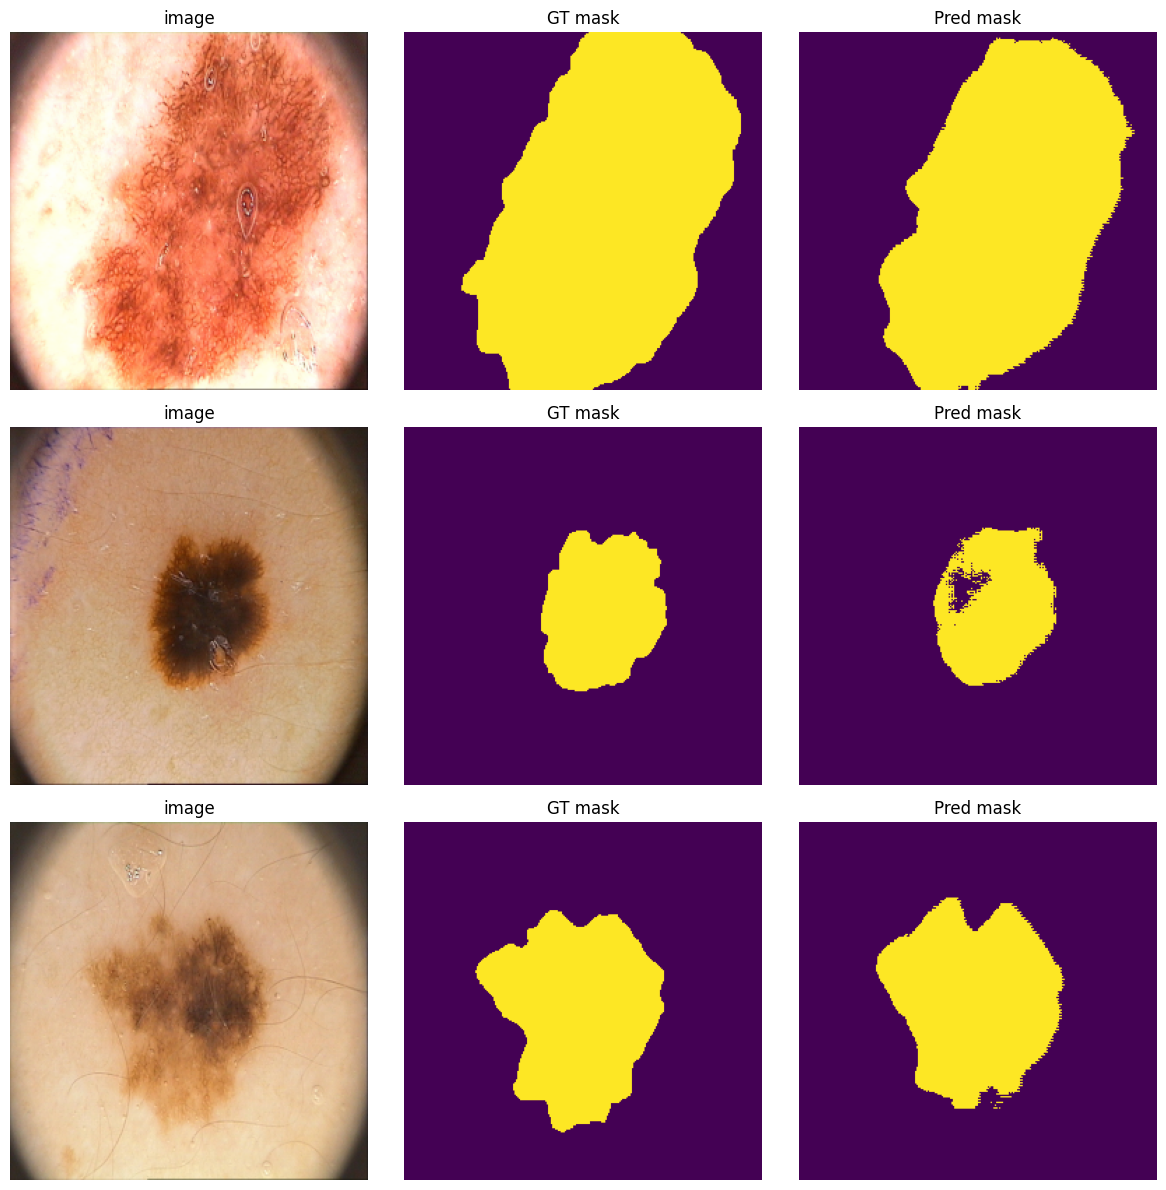

In [58]:
test_loss, test_dice = test(
    model=model,
    test_loader=test_dataloader,
    device=device,
    criterion=criterion,
    checkpoint_state=best_state,
    num_samples=3,
)

# Задания: Мир других лоссов!

## Пробуем другие функции потерь [2 балла]

В данном разделе вам потребуется имплементировать две функции потерь: DICE и Focal loss.


### Dice Loss

**1. Dice coefficient:** Учитывая две маски $X$ и $Y$, общая метрика для измерения расстояния между этими двумя масками задается следующим образом:

$$D(X,Y)=\frac{2|X\cap Y|}{|X|+|Y|}$$

В терминах матрицы ошибок она будет считаться следующим образом:

$$D(X,Y) = \frac{2TP}{2TP + FP + FN}$$

Эта функция не является дифференцируемой, но это необходимое свойство для градиентного спуска. В данном случае мы можем приблизить его с помощью:

$$\mathcal L_D(X,Y) = 1- D(X, Y)$$

**Hints** (!):

1. Не забудьте подумать о численной нестабильности, возникающей в математической формуле при ситуации, когда $\frac{0}{0}$, т.е. вам нужно добавить очень маленькое число, например $\epsilon = 1e^{-8}$, в обе части дроби при подсчете $D(X,Y)$:

$$D(X,Y) = \frac{2TP + ϵ}{2TP + FP + FN + ϵ}$$

2. Dice метрика(!), не лосс, считается похожим образом как IoU:

    2.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    2.2. Фиксируем порог, например threshold=0.5, и всему что ниже порога ставим значение 0, всему что выше 1. Получаем предсказанную маску из 0 и 1.

    2.3. Считаем TP, FP, FN

    2.4. Считаем DICE метрику по формуле

Вы можете прописать для себя функцию `dice_score()` и сравнить с результатами работы функции из библиотеки `torchmetrics`.

3. Но с метрикой есть проблема, что она не дифференцируема, и если вы захотите просто взять и прописать `dice_loss` = 1 - `dice_score`, Pytorch поругается на вас и скажет, что это недифференцируемая метрика. Чтобы посчитать dice_loss делаем следующие шаги:

    3.1. На вход вам приходят logits, т.е. значения от $-∞$ до $∞$. Их переводим в вероятности от 0 до 1 при помощи функции Sigmoid.

    3.2. Здесь нам уже не нужно фиксировать порог, мы просто работаем с вероятностями. Значения вероятностей дифференцируемы и через них будут протекать градиенты.

    3.3. Считаем TP, FP, FN также как и в Dice метрике, только вместо маски, подаем вероятности.

    3.4. Считаем DICE метрику по формуле

    3.5. Считаем лосс как Loss = 1 - DICE

Итак, давайте сначала пропишем dice_score.

In [59]:
def dice_score(logits: torch.Tensor, labels: torch.Tensor, threshold: float = 0.5):
    '''
    Это именно метрика, не лосс.
    '''
    probs = torch.sigmoid(logits)
    labels = labels.float()
    eps = 1e-8
    intersection = (probs * labels).sum()
    union = probs.sum() + labels.sum()

    score = (2.0 * intersection + eps) / (union + eps)
    return score

Проверим на корректность функцию dice_score:

In [60]:
from torchmetrics.segmentation import DiceScore

dice = DiceScore(num_classes=1, average='micro').to(device)
dice(dummpy_sample['logits'].sigmoid(), dummpy_sample['labels'].to(int))
dice_score(dummpy_sample['logits'], dummpy_sample['labels'])

/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: DiceScore metric currently defaults to `average=micro`, but will change to`average=macro` in the v1.9 release. If you've explicitly set this parameter, you can ignore this warning.
  warnings.warn(*args, **kwargs)


tensor(0.4244, device='cuda:0')

In [ ]:
'''
если вы используете версию библиотеки 0.11.4, то можно взять torchmetrics.classification.Dice():

from torchmetrics.classification import Dice

dice = Dice(average='micro').to(device)

'''

In [61]:
assert dice(dummpy_sample['logits'].sigmoid(), dummpy_sample['labels'].to(int)) == dice_score(dummpy_sample['logits'], dummpy_sample['labels'])

AssertionError: 

Давайте теперь пропишем лосс и воспользуемся библиотекой `segmentation-models-pytorch`, чтобы убедиться в корректности нашей функции.

In [62]:
def dice_loss(logits: torch.Tensor, labels: torch.Tensor):

    '''
    Это лосс.
    '''
    labels = labels.float()
    probs = torch.sigmoid(logits)

    probs = probs.view(probs.size(0), -1)
    labels = labels.view(labels.size(0), -1)

    intersection = (probs * labels).sum(dim=1)
    cardinality = probs.sum(dim=1) + labels.sum(dim=1)

    dice = (2.0 * intersection) / (cardinality + 1e-8)
    loss = 1.0 - dice
    return loss.mean()# TODO

Проверка на корректность:

In [63]:
# проверьте, что у вас установлена библиотека
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.1 MB/s eta 0:00:00


In [64]:
from segmentation_models_pytorch.losses import DiceLoss
dice_loss_torch = DiceLoss(mode='binary')
dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'])

tensor(0.5756, device='cuda:0')

In [65]:
assert dice_loss_torch(dummpy_sample['logits'], dummpy_sample['labels'].to(int)) == dice_loss(dummpy_sample['logits'], dummpy_sample['labels'])

### Focal Loss

[**2. Focal loss:**](https://arxiv.org/pdf/1708.02002.pdf)

Окей, мы уже с вами умеем делать BCE loss:

$$\mathcal L_{BCE}(y, \hat y) = -\sum_i \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Проблема с этой потерей заключается в том, что она имеет тенденцию приносить пользу классу **большинства** (фоновому) по отношению к классу **меньшинства** ( переднему). Поэтому обычно применяются весовые коэффициенты к каждому классу:

$$\mathcal L_{wBCE}(y, \hat y) = -\sum_i \alpha_i\left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

Традиционно вес $\alpha_i$ определяется как обратная частота класса этого пикселя $i$, так что наблюдения миноритарного класса весят больше по отношению к классу большинства.


Из оригинальной статьи по [Focal Loss](https://arxiv.org/pdf/1708.02002.pdf):

$$p_t = \sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)$$

$$\mathcal L_{focal}(y, \hat y) = (1 - p_t)^{\gamma} \mathcal L_{BCE}(y_i, \hat y_i).$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - p_t)^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

$$\mathcal L_{focal}(y, \hat y) = -\sum_i (1 - (\sigma(\hat y_i)y_i + (1 - \sigma(\hat y_i)) (1-y_i)))^{\gamma} \left[y_i\log\sigma(\hat y_i) + (1-y_i)\log(1-\sigma(\hat y_i))\right].$$

In [98]:
def focal_loss(logits, targets, gamma = 2.0, eps = 1e-8):
    targets = targets.float()

    probs = torch.sigmoid(logits)
    p_t = probs * targets + (1.0 - probs) * (1.0 - targets)

    bce_term = (
        targets * torch.log(probs.clamp(min=eps)) +
        (1.0 - targets) * torch.log((1.0 - probs).clamp(min=eps))
    )
    modulating = (1.0 - p_t) ** gamma

    loss = - modulating * bce_term

    return loss.sum()


Проверка корректности функции:

In [88]:
from torchvision.ops import sigmoid_focal_loss
sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum')

tensor(3.6161, device='cuda:0')

In [89]:
assert sigmoid_focal_loss(dummpy_sample['logits'], dummpy_sample['labels'], alpha=-1, gamma=2, reduction='sum') == focal_loss(dummpy_sample['labels'], dummpy_sample['logits'], gamma=2.0)

## [BONUS] Мир сегментационных лоссов [5 баллов]

В данном блоке предлагаем вам написать одну функцию потерь самостоятельно. Для этого необходимо прочитать статью и имплементировать ее, и провести численное сравнение с предыдущими функциями.

* [Physiological Inspired Deep Neural Networks for Emotion Recognition](https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=8472816&tag=1)". IEEE Access, 6, 53930-53943.

* [Boundary loss for highly unbalanced segmentation](https://arxiv.org/abs/1812.07032)

* [Tversky loss function for image segmentation using 3D fully convolutional deep networks](https://arxiv.org/abs/1706.05721)

* [Correlation Maximized Structural Similarity Loss for Semantic Segmentation](https://arxiv.org/abs/1910.08711)

* [Topology-Preserving Deep Image Segmentation](https://papers.nips.cc/paper/8803-topology-preserving-deep-image-segmentation)

In [90]:
import torch
import torch.nn as nn

def tversky_loss(logits, labels, alpha = 0.3, beta = 0.7, eps = 1e-8):
    # приводим к float и получаем вероятности
    labels = labels.float()
    probs = torch.sigmoid(logits)

    # все в вектора
    probs_flat = probs.view(-1)
    labels_flat = labels.view(-1)

    TP = (probs_flat * labels_flat).sum()
    FP = (probs_flat * (1.0 - labels_flat)).sum()
    FN = ((1.0 - probs_flat) * labels_flat).sum()

    # индекс Тверски
    tversky_index = (TP + eps) / (TP + alpha * FP + beta * FN + eps)

    loss = 1.0 - tversky_index
    return loss


## Обучите SegNet на новых лоссах

**Задание**: обучите SegNet на новых лоссах и сравните все три лосса:
*   При каком лоссе модель сходится быстрее?
*   При каком лоссе модель выдает наилучшую метрику?

Напишите развернутый ответ на вопросы.



1) *самая быстрая сходимость у dice loss, так как она уже на ~7 эпохе стабильно растет (у BCE резкий рост происходит только после 10й эпохи, а у focal loss самый медленный рост, как можно заметить)*
2) *BCE, так как в своем пике достигает 0.5894, а dice совсем уступает маусимуму со своими 0.5849, но яв-ся более стабильным*

In [91]:
def train_with_dice(model, train_loader, val_loader, criterion, optimizer, device, num_epoch=10):
    model.to(device)
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_dice": [],
        "val_dice": [],
    }
    best_state = None
    best_val_loss = float("inf")

    for epoch in range(1, num_epoch + 1):
        model.train()
        running_train_loss = 0.0
        running_train_dice = 0.0
        n_train_batches = 0

        for images, masks in tqdm(train_loader, desc=f"train {epoch}"):
            images = images.to(device)
            masks = masks.to(device).float()

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()

            batch_size = images.size(0)
            running_train_loss += loss.item() * batch_size

            running_train_dice += dice_score(logits, masks).item()
            n_train_batches += 1

        train_loss = running_train_loss / len(train_loader.dataset)
        train_dice = running_train_dice / n_train_batches

        model.eval()
        running_val_loss = 0.0
        running_val_dice = 0.0
        n_val_batches = 0

        with torch.no_grad():
            for images, masks in tqdm(val_loader, desc=f"val {epoch}"):
                images = images.to(device)
                masks = masks.to(device).float()

                logits = model(images)
                loss = criterion(logits, masks)
                batch_size = images.size(0)

                running_val_loss += loss.item() * batch_size
                running_val_dice += dice_score(logits, masks).item()
                n_val_batches += 1

        val_loss = running_val_loss / len(val_loader.dataset)
        val_dice = running_val_dice / n_val_batches

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_dice"].append(train_dice)
        history["val_dice"].append(val_dice)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())

        print(
            f"epoch: {epoch:02d}: "
            f"train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, "
            f"train_dice={train_dice:.4f}, val_dice={val_dice:.4f}"
        )

    print(f"\nЛучший val_loss: {best_val_loss:.4f}")
    return history, best_state


In [99]:
criterions = {
    "bce": nn.BCEWithLogitsLoss(),
    "dice": dice_loss,
    "focal": focal_loss,
}

results = {}

for name, criterion in criterions.items():
    print(f"\n=== обучаем с лоссом: {name} ===")

    model = SegNet()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    new_history, new_best_state = train_with_dice(
        model=model,
        train_loader=train_dataloader,
        val_loader=valid_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        num_epoch=25,
    )

    results[name] = {
        "history": new_history,
        "best_state": new_best_state,
    }


=== Обучаем с лоссом: bce ===


train 1:   0%|          | 0/4 [00:00<?, ?it/s]

val 1:   0%|          | 0/2 [00:00<?, ?it/s]

KeyboardInterrupt: 

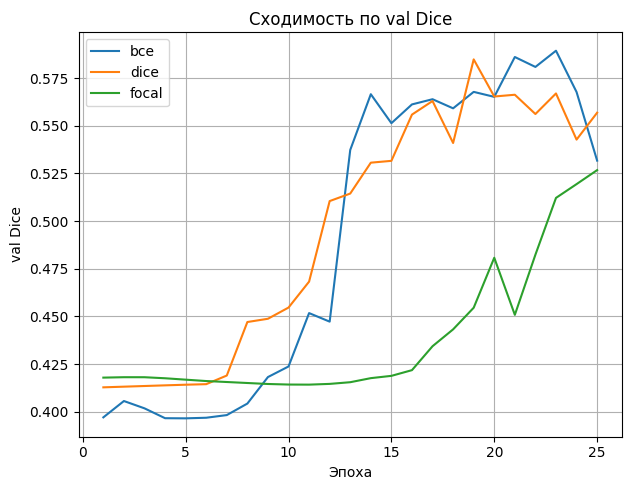

In [93]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 2)
for name, res in results.items():
    val_dice = res["history"]["val_dice"]
    epochs = range(1, len(val_dice) + 1)
    plt.plot(epochs, val_dice, label=name)
plt.title("Сходимость по val Dice")
plt.xlabel("Эпоха")
plt.ylabel("val Dice")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# Задание: Новая модель!

## Модель U-Net [2 балла]

[**U-Net**](https://arxiv.org/abs/1505.04597) — это архитектура нейронной сети, которая получает изображение и выводит его. Первоначально он был задуман для семантической сегментации (как мы ее будем использовать), но он настолько успешен, что с тех пор используется в других контекстах. Получая на вход медицинское изображение, он выведет изображение в оттенках серого, где интенсивность каждого пикселя зависит от вероятности того, что этот пиксель принадлежит интересующей нас области.

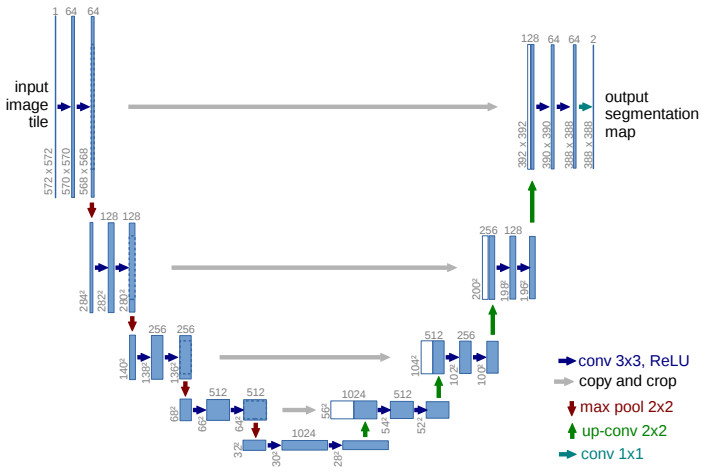

У нас в архитектуре все так же существует энкодер и декодер, как в **SegNet**, но отличительной особеностью данной модели являются *skip-conenctions*, соединяющие части декодера и энкодера. То есть для того чтобы передать на вход декодера тензор, мы конкатенируем симметричный выход с энкодера и выход предыдущего слоя декодера.

* Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "[U-Net: Convolutional networks for biomedical image segmentation.](https://arxiv.org/pdf/1505.04597.pdf)" International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

В оригинальной статье авторы не использовали padding внутри модели (это видно по тому, что размеры карты признаков уменьшаются на 2 каждый раз при движении от слоя к слою). При этом размеры входных изображений авторы единоразово увеличили при помощи mirror padding.

В этом домашнем задании вы можете применить альтернативный подход - сохранять размеры карт признаков при помощью padding = 1 во внутренних слоях.  

In [100]:
import torch.nn.functional as F
import torch.nn as nn

Для реализации UNet вы можете написать классы блоков энкодера и декодера отдельно, как мы сделали при реализации SegNet.

In [110]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self, n_class: int = 1):
        super().__init__()

        self.down1 = DoubleConv(3, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.down2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.down3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        self.down4 = DoubleConv(256, 512)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv4 = DoubleConv(1024, 512)
        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv3 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv2 = DoubleConv(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv1 = DoubleConv(128, 64)

        self.out_conv = nn.Conv2d(64, n_class, kernel_size=1)

    def forward(self, x):
        # encoder
        x1 = self.down1(x)
        x2 = self.down2(self.pool1(x1))
        x3 = self.down3(self.pool2(x2))
        x4 = self.down4(self.pool3(x3))
        x5 = self.bottleneck(self.pool4(x4))

        # decoder и skip connections
        x = self.up4(x5)
        x = torch.cat([x4, x], dim=1)
        x = self.conv4(x)

        x = self.up3(x)
        x = torch.cat([x3, x], dim=1)
        x = self.conv3(x)

        x = self.up2(x)
        x = torch.cat([x2, x], dim=1)
        x = self.conv2(x)

        x = self.up1(x)
        x = torch.cat([x1, x], dim=1)
        x = self.conv1(x)

        output = self.out_conv(x)
        return output


In [102]:
unet_model = UNet().to(device)

## Обучите UNet

Задание: обучите UNet на всех трех лоссах: BCE, Dice, Focal и сравните результаты с SegNet:
*   Какая модель дает лучшие значения по метрике?
*   Какая модель дает лучшие значения по лоссам?
*   Какая модель обучается быстрее?
*   Сравните визуально результаты SegNet и UNet.

Напишите развернутый ответ на вопросы.



1) *unet дает ~0.8 по метрике, что сильно лучше, чем SegNet*
2) *unet дает лучшие значения по всем лоссам*
3) *по числу эпох unet сходится быстрее*
4) *в самом низу графики*

In [106]:
criterions = {
    "bce": nn.BCEWithLogitsLoss(),
    "dice": dice_loss,
    "focal": focal_loss,
}

results_segnet = {}
results_unet = {}

for name, criterion in criterions.items():
    print(f"\n=== SegNet + {name} loss ===")
    model = SegNet()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    new2_history, new2_best_state = train_with_dice(
        model=model,
        train_loader=train_dataloader,
        val_loader=valid_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        num_epoch=10,
    )

    results_segnet[name] = {"history": new2_history, "best_state": new2_best_state}

for name, criterion in criterions.items():
    print(f"\n=== UNet + {name} loss ===")
    unet_model = UNet()
    optimizer = torch.optim.Adam(unet_model.parameters(), lr=1e-3)

    unet_history, unet_best_state = train_with_dice(
        model=unet_model,
        train_loader=train_dataloader,
        val_loader=valid_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        num_epoch=10,
    )

    results_unet[name] = {"history": unet_history, "best_state": unet_best_state}



=== SegNet + bce loss ===


train 1:   0%|          | 0/4 [00:00<?, ?it/s]

val 1:   0%|          | 0/2 [00:00<?, ?it/s]

epoch: 01: train_loss=0.7558, val_loss=0.7382, train_dice=0.4229, val_dice=0.4345


train 2:   0%|          | 0/4 [00:00<?, ?it/s]

val 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (171 outputs left out)

epoch: 09: train_loss=85930.5498, val_loss=1293121.7500, train_dice=0.6822, val_dice=0.5776


train 10:   0%|          | 0/4 [00:00<?, ?it/s]

val 10:   0%|          | 0/2 [00:00<?, ?it/s]

epoch: 10: train_loss=74671.9473, val_loss=182928.3906, train_dice=0.6773, val_dice=0.6525

Лучший val_loss: 182928.3906


In [112]:
def summarize_results(results, model_name):
    print("\n", model_name)
    for loss_name, res in results.items():
        h = res["history"]
        best_val_loss = min(h["val_loss"])
        best_val_dice = max(h["val_dice"])
        epoch_best_dice = int(np.argmax(h["val_dice"])) + 1
        print(
            f"{loss_name:6s} | "
            f"best_val_loss={best_val_loss:.4f}, "
            f"best_val_dice={best_val_dice:.4f} "
            f"(на эпохе {epoch_best_dice})"
        )

summarize_results(results_segnet, "SegNet")
summarize_results(results_unet, "UNet")


 SegNet
bce    | best_val_loss=0.6591, best_val_dice=0.5232 (на эпохе 9)
dice   | best_val_loss=0.6093, best_val_dice=0.4368 (на эпохе 7)
focal  | best_val_loss=215697.0312, best_val_dice=0.4299 (на эпохе 8)

 UNet
bce    | best_val_loss=0.3262, best_val_dice=0.6749 (на эпохе 10)
dice   | best_val_loss=0.2438, best_val_dice=0.7967 (на эпохе 10)
focal  | best_val_loss=182928.3906, best_val_dice=0.6525 (на эпохе 10)


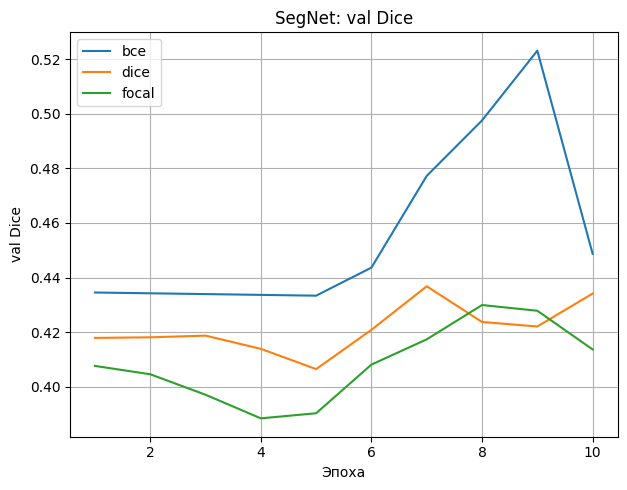

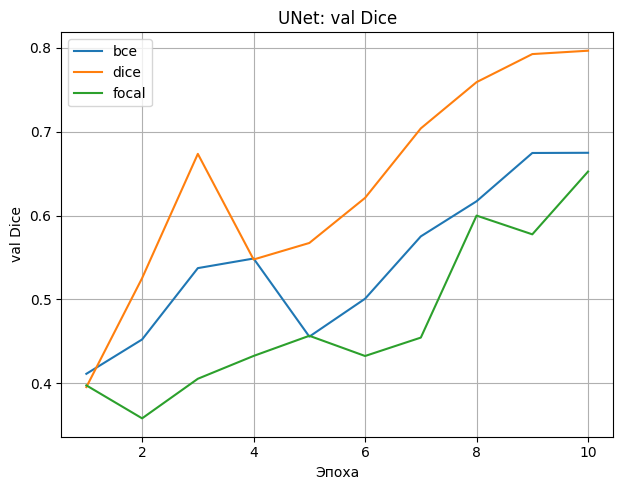

In [109]:
epochs = range(1, 10 + 1)

def plot_model(results, title_prefix):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 2)
    for name, res in results.items():
        plt.plot(epochs, res["history"]["val_dice"], label=name)
    plt.title(f"{title_prefix}: val Dice")
    plt.xlabel("Эпоха")
    plt.ylabel("val Dice")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_model(results_segnet, "SegNet")
plot_model(results_unet, "UNet")